In [24]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random
from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
from scipy.optimize import minimize_scalar

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from visualization import (
    plot_copy_number_heatmap
    )
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)

from visualization import plot_overlap_matrix_figure

import time

In [2]:
numb = "57"
tumor = "t"+numb

In [3]:
#bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt", sep = "\t")
bincounts = pd.read_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells_with_collisions.txt", sep = "\t")#
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")
#cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values

#normal_cells = pd.read_csv(f"../data/{tumor}/normal_cells.txt", header=None, sep="\t")[0].values

In [4]:
previous_A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")
# previous_B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B.txt", sep="\t")
previous_C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")
# previous_D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D.txt", sep="\t")

In [5]:
previous_A_dict = {}
for cluster in previous_A_df['population'].unique():
    print(cluster)
    cells_in_cluster = previous_A_df[previous_A_df['population'] == cluster]['cell'].tolist()
    previous_A_dict[cluster] = {
        'cells': cells_in_cluster
    }
previous_C_dict = {}
for cluster in previous_C_df['population'].unique():
    print(cluster)
    cells_in_cluster = previous_C_df[previous_C_df['population'] == cluster]['cell'].tolist()
    previous_C_dict[cluster] = {
        'cells': cells_in_cluster
    }
    

A11
A121
A122
A21
A22
C11
C12
C211
C212
C2211
C22121
C22122
C2221
C2222


In [6]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A_with_collisions.txt", sep="\t")
B_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_B_with_collisions.txt", sep="\t")
C_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C_with_collisions.txt", sep="\t")
D_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_D_with_collisions.txt", sep="\t")
equi_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt", sep="\t")
#C_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_C_WGS_with_broken_cells.txt", sep="\t")

In [7]:
cells = A_df["cell"].values

In [8]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

A1111
A1112
A1121
A11221
A11222
A121
A122
A21
A22


In [9]:
B_dict = {}
for cluster in B_df['population'].unique():
    print(cluster)
    cells_in_cluster = B_df[B_df['population'] == cluster]['cell'].tolist()
    B_dict[cluster] = {
        'cells': cells_in_cluster
    }

B11
B12
B211
B2121
B2122
B22


In [10]:
C_dict = {}
for cluster in C_df['population'].unique():
    print(cluster)
    cells_in_cluster = C_df[C_df['population'] == cluster]['cell'].tolist()
    C_dict[cluster] = {
        'cells': cells_in_cluster
    }

C11
C12
C21
C22111
C22112
C2212
C2221
C2222


In [11]:
D_dict = {}
for cluster in D_df['population'].unique():
    print(cluster)
    cells_in_cluster = D_df[D_df['population'] == cluster]['cell'].tolist()
    D_dict[cluster] = {
        'cells': cells_in_cluster
    }

D11
D121
D1221
D1222
D21
D22


In [13]:
previous_A_dict["collisions"] = {"cells": [c for c in cells if "_" in c]}
previous_C_dict["collisions"] = {"cells": [c for c in cells if "_" in c]}

In [14]:
# Prepare the data - create the data DataFrame with segment info
data = bincounts[["chrom","abstart", "abend"]].copy()
#data_no_WGS = bincounts_no_WGS[["chrom","abstart", "abend"]].copy()
for cell in cells:
    if cell in bincounts.columns:
        data[cell] = bincounts[cell].values
        #data_no_WGS[cell] = bincounts_no_WGS[cell].values
data["lengths"] = data["abend"] - data["abstart"]
#data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]

# Get just the cell count data for analysis
all_data = data[cells].copy()
#all_data_no_WGS = data_no_WGS[cells].copy()

In [15]:
# Identify normal populations and compute ratios for both A and B populations
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



=== Population Set A Analysis ===
Normal population identified as: A22
Mean read count ratio for population A1111 relative to normal (A22): 1.23
Mean read count ratio for population A1112 relative to normal (A22): 1.78
Mean read count ratio for population A1121 relative to normal (A22): 1.31
Mean read count ratio for population A11221 relative to normal (A22): 1.25
Mean read count ratio for population A11222 relative to normal (A22): 1.26
Mean read count ratio for population A121 relative to normal (A22): 1.13
Mean read count ratio for population A122 relative to normal (A22): 1.24
Mean read count ratio for population A21 relative to normal (A22): 1.70
Mean read count ratio for population A22 relative to normal (A22): 1.00
=== Population Set B Analysis ===
Normal population identified as: B11
Mean read count ratio for population B11 relative to normal (B11): 1.00
Mean read count ratio for population B12 relative to normal (B11): 1.67
Mean read count ratio for population B211 relative t

In [16]:
#Add normal to the A_df population assignments
A_df["normal_population"] = (A_df['population'] == normal_A)
B_df["normal_population"] = (B_df['population'] == normal_B)
C_df["normal_population"] = (C_df['population'] == normal_C)
D_df["normal_population"] = (D_df['population'] == normal_D)

In [17]:
data_lengths = data["abend"] - data["abstart"]

In [18]:
readcount_dict = dict(all_data.sum())

In [19]:
# readcount_dict in increasing order by values
readcount_dict = dict(sorted(readcount_dict.items(), key=lambda item: item[1]))

In [20]:
# order A_dict["A11"]["cells"] by readcount_dict
for cluster in A_dict:
    A_dict[cluster]["cells"] = sorted(A_dict[cluster]["cells"], key=lambda cell: readcount_dict[cell])


Overlap Matrix (A rows vs B cols):
Pop          A11    A121    A122     A21     A22collisions
B11            0       0       0    1603       0       7
B12            0       1       0       1      65      51
B211         283       0       0       0       0       1
B2121         82       0       0       0       0       0
B2122         28       0       2       1      21      29
B22            0     135     208       0       0      12


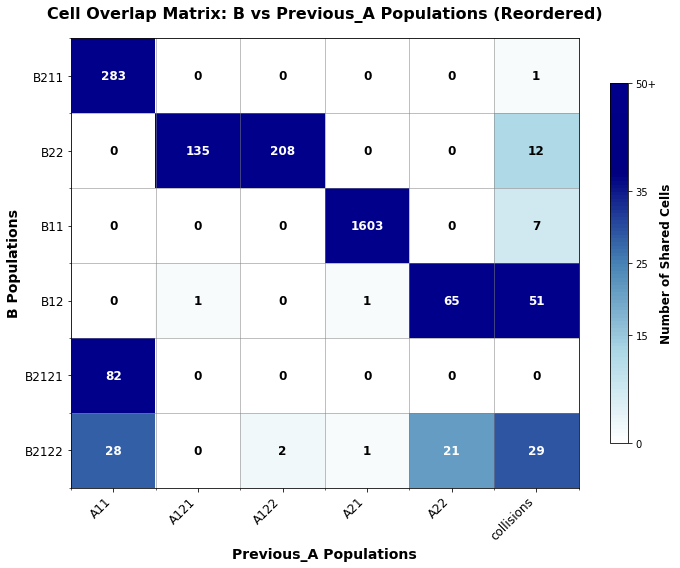

In [66]:
overlap_df = plot_overlap_matrix_figure(B_dict, previous_A_dict, name1="B", name2="Previous_A")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12    C211    C212   C2211  C22121  C22122   C2221   C2222collisions
A1111          0       0       0       0       0       0       0       0      80       0
A1112          0       0       0       0       0       0       1      43       0      28
A1121          0       0       0       0     157       0       1       0       0       1
A11221         0       0       0       0       3       0      94       0       0       0
A11222         0       0       0       0       0      35       2       0       0       1
A121           0       0     136       0       0       0       0       0       0       3
A122           0       0       0     209       0       0       0       0       0      11
A21            1      64       0       0       0       0       0       0       0      50
A22         1602       2       0       0       0       0       0       0       0       6


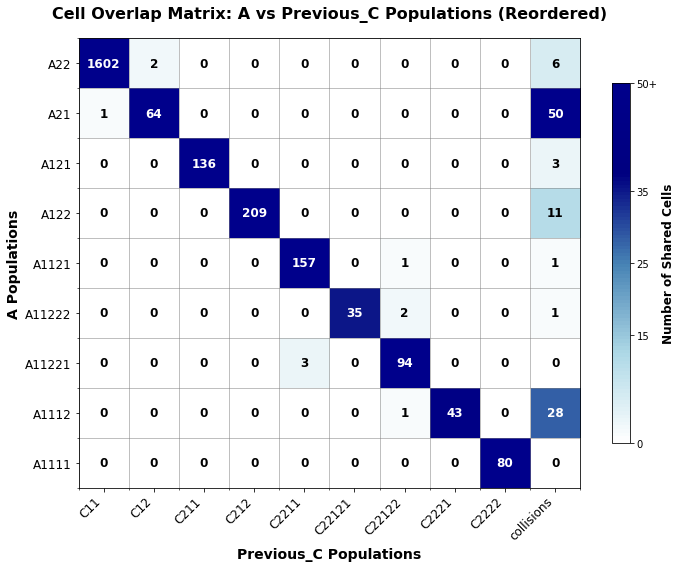

In [36]:
overlap_df = plot_overlap_matrix_figure(A_dict, previous_C_dict, name1="A", name2="Previous_C")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12    C211    C212   C2211  C22121  C22122   C2221   C2222collisions
B11         1603       0       0       0       0       0       0       0       0       7
B12            0      66       1       0       0       0       0       0       0      51
B211           0       0       0       0     159      31      93       0       0       1
B2121          0       0       0       0       1       0       1       0      80       0
B2122          0       0       0       1       0       4       4      43       0      29
B22            0       0     135     208       0       0       0       0       0      12


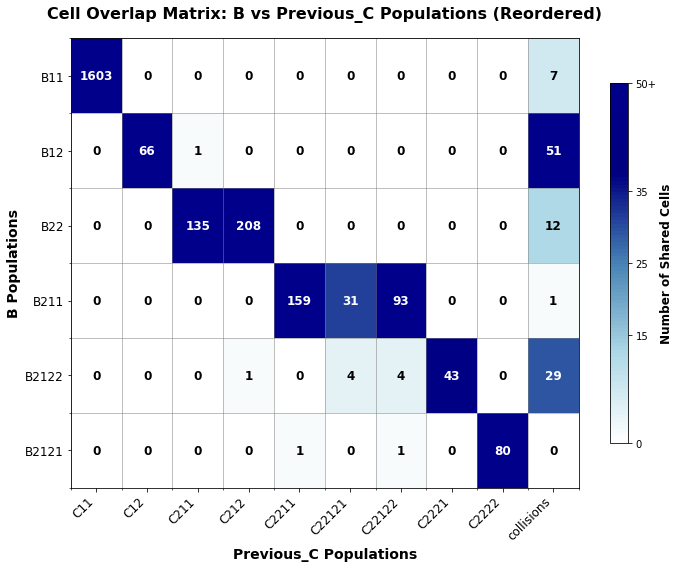

In [37]:
overlap_df = plot_overlap_matrix_figure(B_dict, previous_C_dict, name1="B", name2="Previous_C")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12    C211    C212   C2211  C22121  C22122   C2221   C2222collisions
C11         1603       0       0       0       0       0       0       0       0       7
C12            0      66       1       0       0       0       0       0       0      51
C21            0       0     135     208       0       0       0       0       0      13
C22111         0       0       0       0       1       0      95       0       0       1
C22112         0       0       0       0       0      35       2       0       0       1
C2212          0       0       0       0     159       0       0       0       0       0
C2221          0       0       0       1       0       0       1      43       1      27
C2222          0       0       0       0       0       0       0       0      79       0


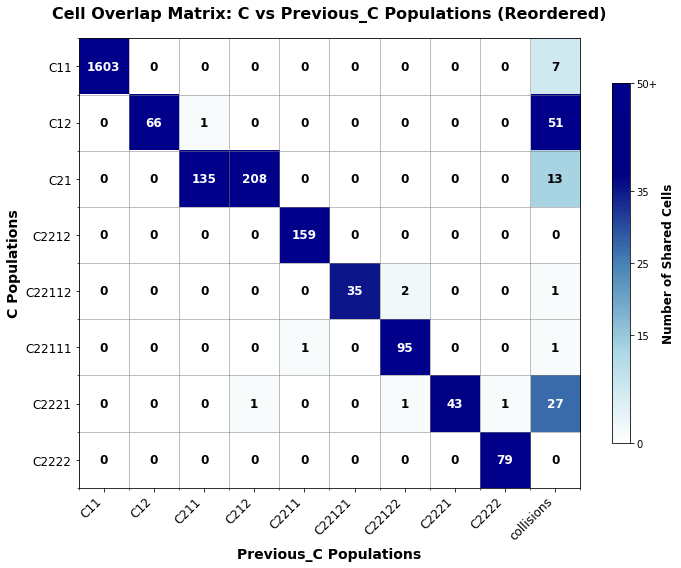

In [38]:
overlap_df = plot_overlap_matrix_figure(C_dict, previous_C_dict, name1="C", name2="Previous_C")


Overlap Matrix (A rows vs B cols):
Pop          C11     C12    C211    C212   C2211  C22121  C22122   C2221   C2222collisions
D11            0       0     135     208       0       0       0       0       0      13
D121           0       0       0       0     159      32      94       0       0       2
D1221          0       0       0       0       1       0       1       0      80       0
D1222          0       0       0       1       0       3       3      43       0      27
D21         1603       0       0       0       0       0       0       0       0       7
D22            0      66       1       0       0       0       0       0       0      51


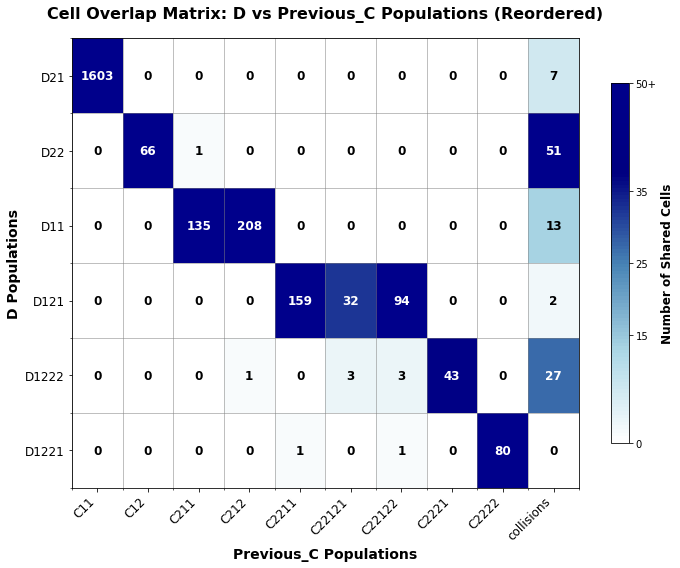

In [39]:
overlap_df = plot_overlap_matrix_figure(D_dict, previous_C_dict, name1="D", name2="Previous_C")

In [40]:
def create_copy_number_matrix_fast_new(all_data, reassigned_populations, ratios_to_normal, normal_pop_name, readcount_dict):
   
    import numpy as np
    import pandas as pd
    
    for cluster in reassigned_populations:
        reassigned_populations[cluster]["cells"] = sorted(reassigned_populations[cluster]["cells"], key=lambda cell: readcount_dict[cell])
    # Create cell to population mapping
    cell_pop_mapping = {}
    for pop_name, pop_data in reassigned_populations.items():
        for cell in pop_data["cells"]:
            cell_pop_mapping[cell] = pop_name
    
    # Order cells by population
    ordered_cells = []
    pop_boundaries = []
    current_pos = 0
    
    # Add normal population first
    normal_cells = reassigned_populations[normal_pop_name]["cells"]
    ordered_cells.extend(normal_cells)
    current_pos += len(normal_cells)
    pop_boundaries.append((normal_pop_name, 0, current_pos))
    
    # Add other populations
    for pop_name in reassigned_populations.keys():
        if pop_name != normal_pop_name:
            pop_cells = reassigned_populations[pop_name]["cells"]
            ordered_cells.extend(pop_cells)
            start_pos = current_pos
            current_pos += len(pop_cells)
            pop_boundaries.append((pop_name, start_pos, current_pos))
    
    # Order segments by chromosome and position
    segment_order = ratios_to_normal[['chrom', 'start', 'end']].copy()
    chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
    segment_order['chrom_num'] = segment_order['chrom'].apply(
        lambda x: chrom_order.index(x) if x in chrom_order else 999
    )
    segment_order = segment_order.sort_values(['chrom_num', 'start']).reset_index(drop=True)
    ordered_segment_indices = segment_order.index
    
    # Get ordered data (this is the key optimization)
    ordered_data = all_data.iloc[ordered_segment_indices][ordered_cells]
    
    print(f"Processing {len(ordered_segment_indices)} segments using vectorized operations...")
    
    # Step 1: Compute normal_factor (segment average for normal cells)
    normal_cells_data = ordered_data.loc[:, ordered_data.columns.isin(normal_cells)]
    normal_factor = normal_cells_data.mean(axis=1).values  # Average across normal cells for each segment
    normal_factor = np.where(normal_factor > 0, normal_factor, 1)  # Avoid division by zero
    
    print("Normal factor computed")
    
    # Step 2: Normalize all cells by normal_factor
    normalized_data = ordered_data.div(normal_factor, axis=0)
    
    print("Data normalized by normal factor")
    
    # # Step 3: For each cell, normalize by mean over all segments in that cell
    # cell_means = normalized_data.mean(axis=0)  # Mean for each cell across all segments
    # cell_means = np.where(cell_means > 0, cell_means, 1)  # Avoid division by zero
    
    # # Normalize each cell by its own mean
    # doubly_normalized_data = normalized_data.div(cell_means, axis=1)
    
    print("Data normalized by cell means")
    
    # Step 4: Apply ploidy multipliers
    heatmap_data = np.zeros_like(normalized_data.values, dtype=float)
    
    for i, cell in enumerate(ordered_cells):
        cell_pop = cell_pop_mapping[cell]
        
        # # Get appropriate multiplier
        # if cell_pop == normal_pop_name:
        #     multiplier = 2.0  # Normal cells get multiplier of 2
        # else:
        #     pop_ratio_col = f"{cell_pop}_ratio"
        #     multiplier = ploidies.get(pop_ratio_col, 2.0)  # Use ploidy multiplier or default to 2
        
        multiplier = 2
        # Apply multiplier to this cell's data
        heatmap_data[:, i] = normalized_data.iloc[:, i].values * multiplier
    
    print("Ploidy multipliers applied")
    
    # Create segment labels
    segment_labels = [
        f"{segment_order.loc[seg_idx, 'chrom']}:{segment_order.loc[seg_idx, 'start']}-{segment_order.loc[seg_idx, 'end']}"
        for seg_idx in ordered_segment_indices
    ]
    
    # Create heatmap DataFrame
    heatmap_df = pd.DataFrame(heatmap_data, columns=ordered_cells, index=segment_labels)
    
    # Create segment info DataFrame
    segment_info = segment_order[['chrom', 'start', 'end', 'chrom_num']].copy()
    segment_info.index = segment_labels
    
    print("Copy number matrix created successfully!")
    
    return heatmap_df, cell_pop_mapping, pop_boundaries, segment_info


In [41]:
#heatmap_df_A, cell_pop_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast_new(all_data, A_dict, ratios_A, normal_A, readcount_dict)

In [42]:
# plot_copy_number_heatmap(
#     heatmap_df_A, 
#     boundaries_A, 
#     segment_info_A,
#     title="Copy Number Heatmap: Population Set A"
# )


In [43]:
# heatmap_df_D, cell_pop_mapping_D, boundaries_D, segment_info_D = create_copy_number_matrix_fast_new(all_data, D_dict, ratios_D, normal_D, readcount_dict)

In [44]:
# plot_copy_number_heatmap(
#     heatmap_df_D, 
#     boundaries_D, 
#     segment_info_D,
#     title="Copy Number Heatmap: Population Set D"
# )

In [45]:
bincounts.head()

,chrom,loc.start,loc.end,abstart,abend,AAAACCAACCTGATAAC,AAAACCAACTTTTGACG,AAAACCAATTTCAGTAC,AAAACCACTGGCCTTAC,AAAACCAGCTTAGATAC,...,GTTTCGTGGCGATGACG_CCTTTAAAAATGAGTGT,GTTTCGAGCCTCCTTGT_GTGCATAGTTTGTGAAC,TCTTGAAATACTTAACA_TTTCGATTCCAGAGAAG,ATGGCGATGAGGTAAGC_GACCCTATGCACGATCG,TGAAGGAGCGTTATACG_TTGGGAAGTTTGCTACT,AGGACCCTTGGCTCAAG_CAAGGACCTGCATGACG,GGGTCTATGAGGGTATG_TTTCGATTGCTGTCACT,GGTGCAATCGAGAGACT_GGTTTAAGCCTCGGTTG,ATGAGAGTTTTATGATA_AACGATATTTACCAACG,CATGTGATTTACTGATA_ACAGGGAAGCGTAGTTA
0,chr1,0,45387037,0,45387037,570,1604,403,1325,853,...,2564,987,1786,2114,2070,3913,1103,2392,2960,1292
1,chr1,45972336,119478274,45972336,119478274,928,5401,596,4437,2675,...,5287,1909,4193,4295,4176,7572,2384,4707,5534,2643
2,chr1,120035598,175362842,120035598,175362842,506,2172,294,1671,1987,...,2725,889,2308,2707,2346,3581,947,2269,3321,1257
3,chr1,175900450,182029442,175900450,182029442,83,230,66,184,232,...,507,119,435,318,304,626,146,349,475,206
4,chr1,182578512,248389233,182578512,248389233,819,2760,612,1954,1335,...,4019,1313,3184,2455,2572,5586,1734,3216,4010,1867


In [46]:
reassigned_populations = A_dict  # or D_dict, depending on which one you want to use    
normal_pop_name = normal_A  # or normal_D, depending on which one you want to use
ratios_to_normal = ratios_A  # or ratios_D, depending on which one you want to use

for cluster in reassigned_populations:
    reassigned_populations[cluster]["cells"] = sorted(reassigned_populations[cluster]["cells"], key=lambda cell: readcount_dict[cell])
# Create cell to population mapping
cell_pop_mapping = {}
for pop_name, pop_data in reassigned_populations.items():
    for cell in pop_data["cells"]:
        cell_pop_mapping[cell] = pop_name

# Order cells by population
ordered_cells = []
pop_boundaries = []
current_pos = 0

# Add normal population first
normal_cells = reassigned_populations[normal_pop_name]["cells"]
ordered_cells.extend(normal_cells)
current_pos += len(normal_cells)
pop_boundaries.append((normal_pop_name, 0, current_pos))

# Add other populations
for pop_name in reassigned_populations.keys():
    if pop_name != normal_pop_name:
        pop_cells = reassigned_populations[pop_name]["cells"]
        ordered_cells.extend(pop_cells)
        start_pos = current_pos
        current_pos += len(pop_cells)
        pop_boundaries.append((pop_name, start_pos, current_pos))

# Order segments by chromosome and position
segment_order = ratios_to_normal[['chrom', 'start', 'end']].copy()
chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
segment_order['chrom_num'] = segment_order['chrom'].apply(
    lambda x: chrom_order.index(x) if x in chrom_order else 999
)
segment_order = segment_order.sort_values(['chrom_num', 'start']).reset_index(drop=True)
ordered_segment_indices = segment_order.index

# Get ordered data (this is the key optimization)
ordered_data = all_data.iloc[ordered_segment_indices][ordered_cells]

print(f"Processing {len(ordered_segment_indices)} segments using vectorized operations...")

# Step 1: Compute normal_factor (segment average for normal cells)
normal_cells_data = ordered_data.loc[:, ordered_data.columns.isin(normal_cells)]
normal_factor = normal_cells_data.mean(axis=1).values  # Average across normal cells for each segment
normal_factor = np.where(normal_factor > 0, normal_factor, 0.1)  # Avoid division by zero
normal_factor = normal_factor/normal_factor.mean()  # Normalize normal_factor to have mean of 1

print("Normal factor computed")

ordered_data = ordered_data/ordered_data.mean(axis=0)



Processing 89 segments using vectorized operations...
Normal factor computed


In [47]:
# Step 2: Normalize all cells by normal_factor
normalized_data = ordered_data.div(normal_factor, axis=0)

print("Data normalized by normal factor")

# # Step 3: For each cell, normalize by mean over all segments in that cell
# cell_means = normalized_data.mean(axis=0)  # Mean for each cell across all segments
# cell_means = np.where(cell_means > 0, cell_means, 1)  # Avoid division by zero

# # Normalize each cell by its own mean
# doubly_normalized_data = normalized_data.div(cell_means, axis=1)

print("Data normalized by cell means")

# Step 4: Apply ploidy multipliers
heatmap_data = np.zeros_like(normalized_data.values, dtype=float)

for i, cell in enumerate(ordered_cells):
    cell_pop = cell_pop_mapping[cell]
    
    # # Get appropriate multiplier
    # if cell_pop == normal_pop_name:
    #     multiplier = 2.0  # Normal cells get multiplier of 2
    # else:
    #     pop_ratio_col = f"{cell_pop}_ratio"
    #     multiplier = ploidies.get(pop_ratio_col, 2.0)  # Use ploidy multiplier or default to 2
    
    multiplier = 2
    # Apply multiplier to this cell's data
    heatmap_data[:, i] = normalized_data.iloc[:, i].values * multiplier

print("Ploidy multipliers applied")

# Create segment labels
segment_labels = [
    f"{segment_order.loc[seg_idx, 'chrom']}:{segment_order.loc[seg_idx, 'start']}-{segment_order.loc[seg_idx, 'end']}"
    for seg_idx in ordered_segment_indices
]

# Create heatmap DataFrame
heatmap_df = pd.DataFrame(heatmap_data, columns=ordered_cells, index=segment_labels)

# Create segment info DataFrame
segment_info = segment_order[['chrom', 'start', 'end', 'chrom_num']].copy()
segment_info.index = segment_labels

print("Copy number matrix created successfully!")


Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


In [48]:
def create_copy_number_matrix_new(all_data, reassigned_populations, ratios_to_normal, normal_pop_name, readcount_dict):
   
    import numpy as np
    import pandas as pd
    
    for cluster in reassigned_populations:
        reassigned_populations[cluster]["cells"] = sorted(reassigned_populations[cluster]["cells"], key=lambda cell: readcount_dict[cell])
    # Create cell to population mapping
    cell_pop_mapping = {}
    for pop_name, pop_data in reassigned_populations.items():
        for cell in pop_data["cells"]:
            cell_pop_mapping[cell] = pop_name
    
    # Order cells by population
    ordered_cells = []
    pop_boundaries = []
    current_pos = 0
    
    # Add normal population first
    normal_cells = reassigned_populations[normal_pop_name]["cells"]
    ordered_cells.extend(normal_cells)
    current_pos += len(normal_cells)
    pop_boundaries.append((normal_pop_name, 0, current_pos))
    
    # Add other populations
    for pop_name in reassigned_populations.keys():
        if pop_name != normal_pop_name:
            pop_cells = reassigned_populations[pop_name]["cells"]
            ordered_cells.extend(pop_cells)
            start_pos = current_pos
            current_pos += len(pop_cells)
            pop_boundaries.append((pop_name, start_pos, current_pos))
    
    # Order segments by chromosome and position
    segment_order = ratios_to_normal[['chrom', 'start', 'end']].copy()
    chrom_order = ['chr' + str(i) for i in range(1, 23)] + ['chrX']
    segment_order['chrom_num'] = segment_order['chrom'].apply(
        lambda x: chrom_order.index(x) if x in chrom_order else 999
    )
    segment_order = segment_order.sort_values(['chrom_num', 'start']).reset_index(drop=True)
    ordered_segment_indices = segment_order.index
    
    # Get ordered data (this is the key optimization)
    ordered_data = all_data.iloc[ordered_segment_indices][ordered_cells]
    
    print(f"Processing {len(ordered_segment_indices)} segments using vectorized operations...")
    
    # Step 1: Compute normal_factor (segment average for normal cells)
    normal_cells_data = ordered_data.loc[:, ordered_data.columns.isin(normal_cells)]
    normal_factor = normal_cells_data.mean(axis=1).values  # Average across normal cells for each segment
    normal_factor = np.where(normal_factor > 0, normal_factor, 1)  # Avoid division by zero
    normal_factor = np.where(normal_factor > 0, normal_factor, 0.1)  # Avoid division by zero
    normal_factor = normal_factor/normal_factor.mean()  # Normalize normal_factor to have mean of 1

    print("Normal factor computed")

    ordered_data = ordered_data/ordered_data.mean(axis=0)

    # Step 2: Normalize all cells by normal_factor
    normalized_data = ordered_data.div(normal_factor, axis=0)
    
    print("Data normalized by normal factor")
    
    # # Step 3: For each cell, normalize by mean over all segments in that cell
    # cell_means = normalized_data.mean(axis=0)  # Mean for each cell across all segments
    # cell_means = np.where(cell_means > 0, cell_means, 1)  # Avoid division by zero
    
    # # Normalize each cell by its own mean
    # doubly_normalized_data = normalized_data.div(cell_means, axis=1)
    
    print("Data normalized by cell means")
    
    # Step 4: Apply ploidy multipliers
    heatmap_data = np.zeros_like(normalized_data.values, dtype=float)
    
    for i, cell in enumerate(ordered_cells):
        cell_pop = cell_pop_mapping[cell]
        
        # # Get appropriate multiplier
        # if cell_pop == normal_pop_name:
        #     multiplier = 2.0  # Normal cells get multiplier of 2
        # else:
        #     pop_ratio_col = f"{cell_pop}_ratio"
        #     multiplier = ploidies.get(pop_ratio_col, 2.0)  # Use ploidy multiplier or default to 2
        
        multiplier = 2
        # Apply multiplier to this cell's data
        heatmap_data[:, i] = normalized_data.iloc[:, i].values * multiplier
    
    print("Ploidy multipliers applied")
    
    # Create segment labels
    segment_labels = [
        f"{segment_order.loc[seg_idx, 'chrom']}:{segment_order.loc[seg_idx, 'start']}-{segment_order.loc[seg_idx, 'end']}"
        for seg_idx in ordered_segment_indices
    ]
    
    # Create heatmap DataFrame
    heatmap_df = pd.DataFrame(heatmap_data, columns=ordered_cells, index=segment_labels)
    
    # Create segment info DataFrame
    segment_info = segment_order[['chrom', 'start', 'end', 'chrom_num']].copy()
    segment_info.index = segment_labels
    
    print("Copy number matrix created successfully!")
    
    return heatmap_df, cell_pop_mapping, pop_boundaries, segment_info, normalized_data


In [49]:
heatmap_df_A, cell_pop_mapping_A, boundaries_A, segment_info_A , normalized_data_A = create_copy_number_matrix_new(all_data, A_dict, ratios_A, normal_A, readcount_dict)

Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


Expanding heatmap from 89 segments to 5431 rows...

Chromosome representation in heatmap:
chr1: 453 rows, 246,159,932 bp total
chr2: 434 rows, 235,824,599 bp total
chr3: 360 rows, 196,141,480 bp total
chr4: 339 rows, 183,819,298 bp total
chr5: 329 rows, 178,463,482 bp total
chr6: 307 rows, 166,930,960 bp total
chr7: 289 rows, 156,878,815 bp total
chr8: 268 rows, 145,153,934 bp total
chr9: 240 rows, 130,597,528 bp total
chr10: 244 rows, 132,750,269 bp total
chr11: 243 rows, 132,171,512 bp total
chr12: 234 rows, 127,192,322 bp total
chr13: 209 rows, 113,902,193 bp total
chr14: 194 rows, 105,604,444 bp total
chr15: 184 rows, 100,011,182 bp total
chr16: 142 rows, 77,331,877 bp total
chr17: 136 rows, 73,991,953 bp total
chr18: 143 rows, 77,454,799 bp total
chr19: 107 rows, 57,963,957 bp total
chr20: 114 rows, 61,810,229 bp total
chr21: 88 rows, 47,543,707 bp total
chr22: 92 rows, 49,488,653 bp total
chrX: 282 rows, 153,345,065 bp total


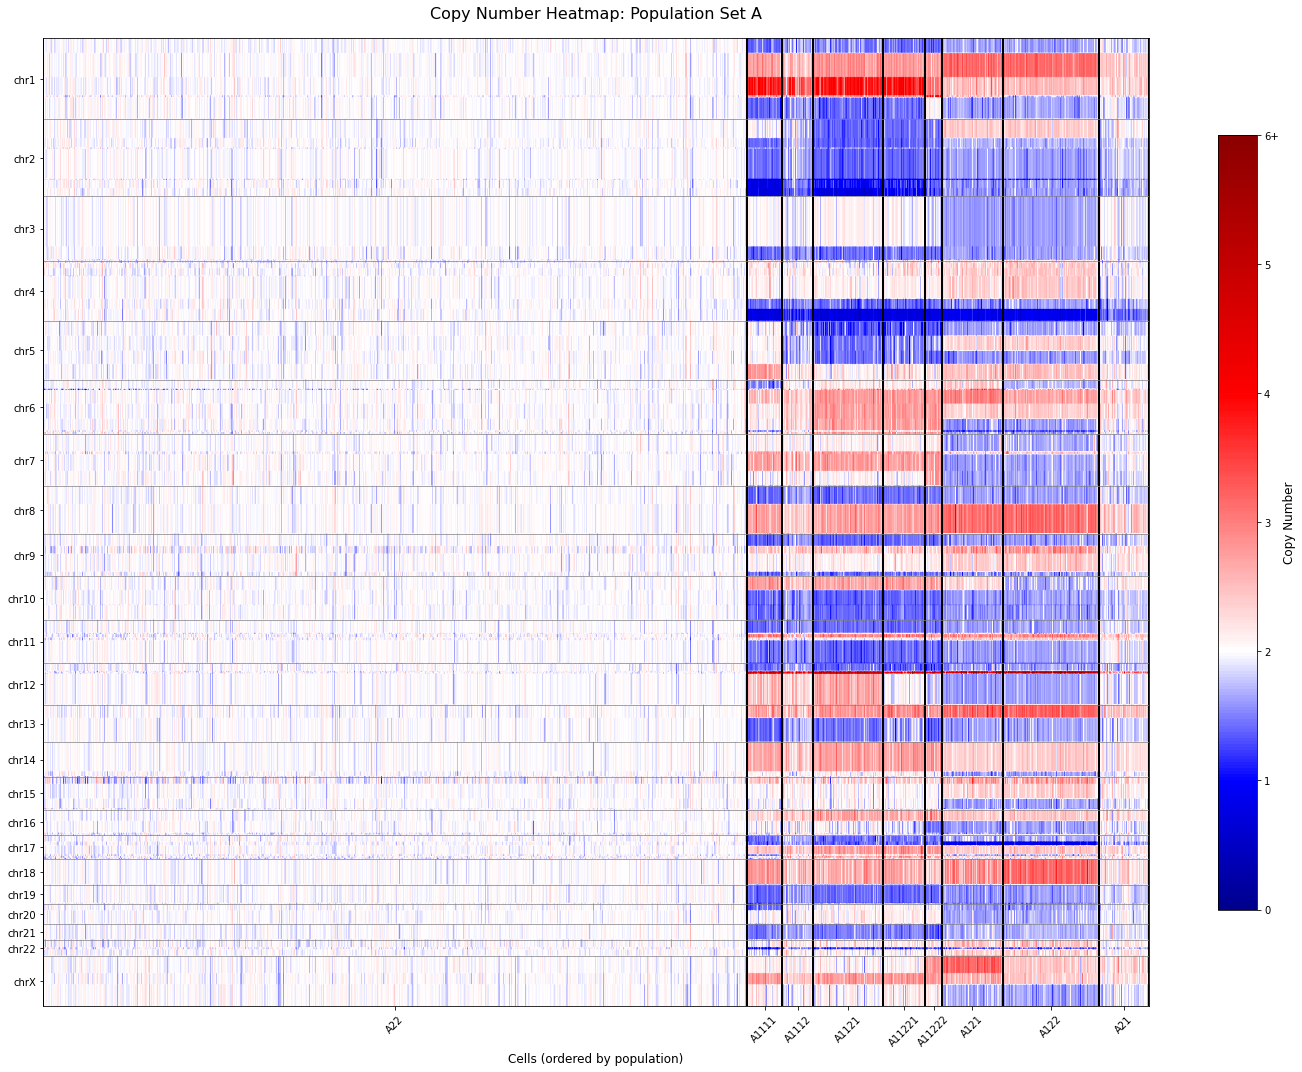

In [50]:
plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

In [51]:
heatmap_df_D, cell_pop_mapping_D, boundaries_D, segment_info_D, normalized_data_D = create_copy_number_matrix_new(all_data, D_dict, ratios_D, normal_D, readcount_dict)

Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


In [52]:
heatmap_df_B, cell_pop_mapping_B, boundaries_B, segment_info_B, normalized_data_B = create_copy_number_matrix_new(all_data, B_dict, ratios_B, normal_B, readcount_dict)
heatmap_df_C, cell_pop_mapping_C, boundaries_C, segment_info_C, normalized_data_C = create_copy_number_matrix_new(all_data, C_dict, ratios_C, normal_C, readcount_dict)

Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!
Processing 89 segments using vectorized operations...
Normal factor computed
Data normalized by normal factor
Data normalized by cell means
Ploidy multipliers applied
Copy number matrix created successfully!


Expanding heatmap from 89 segments to 5431 rows...

Chromosome representation in heatmap:
chr1: 453 rows, 246,159,932 bp total
chr2: 434 rows, 235,824,599 bp total
chr3: 360 rows, 196,141,480 bp total
chr4: 339 rows, 183,819,298 bp total
chr5: 329 rows, 178,463,482 bp total
chr6: 307 rows, 166,930,960 bp total
chr7: 289 rows, 156,878,815 bp total
chr8: 268 rows, 145,153,934 bp total
chr9: 240 rows, 130,597,528 bp total
chr10: 244 rows, 132,750,269 bp total
chr11: 243 rows, 132,171,512 bp total
chr12: 234 rows, 127,192,322 bp total
chr13: 209 rows, 113,902,193 bp total
chr14: 194 rows, 105,604,444 bp total
chr15: 184 rows, 100,011,182 bp total
chr16: 142 rows, 77,331,877 bp total
chr17: 136 rows, 73,991,953 bp total
chr18: 143 rows, 77,454,799 bp total
chr19: 107 rows, 57,963,957 bp total
chr20: 114 rows, 61,810,229 bp total
chr21: 88 rows, 47,543,707 bp total
chr22: 92 rows, 49,488,653 bp total
chrX: 282 rows, 153,345,065 bp total


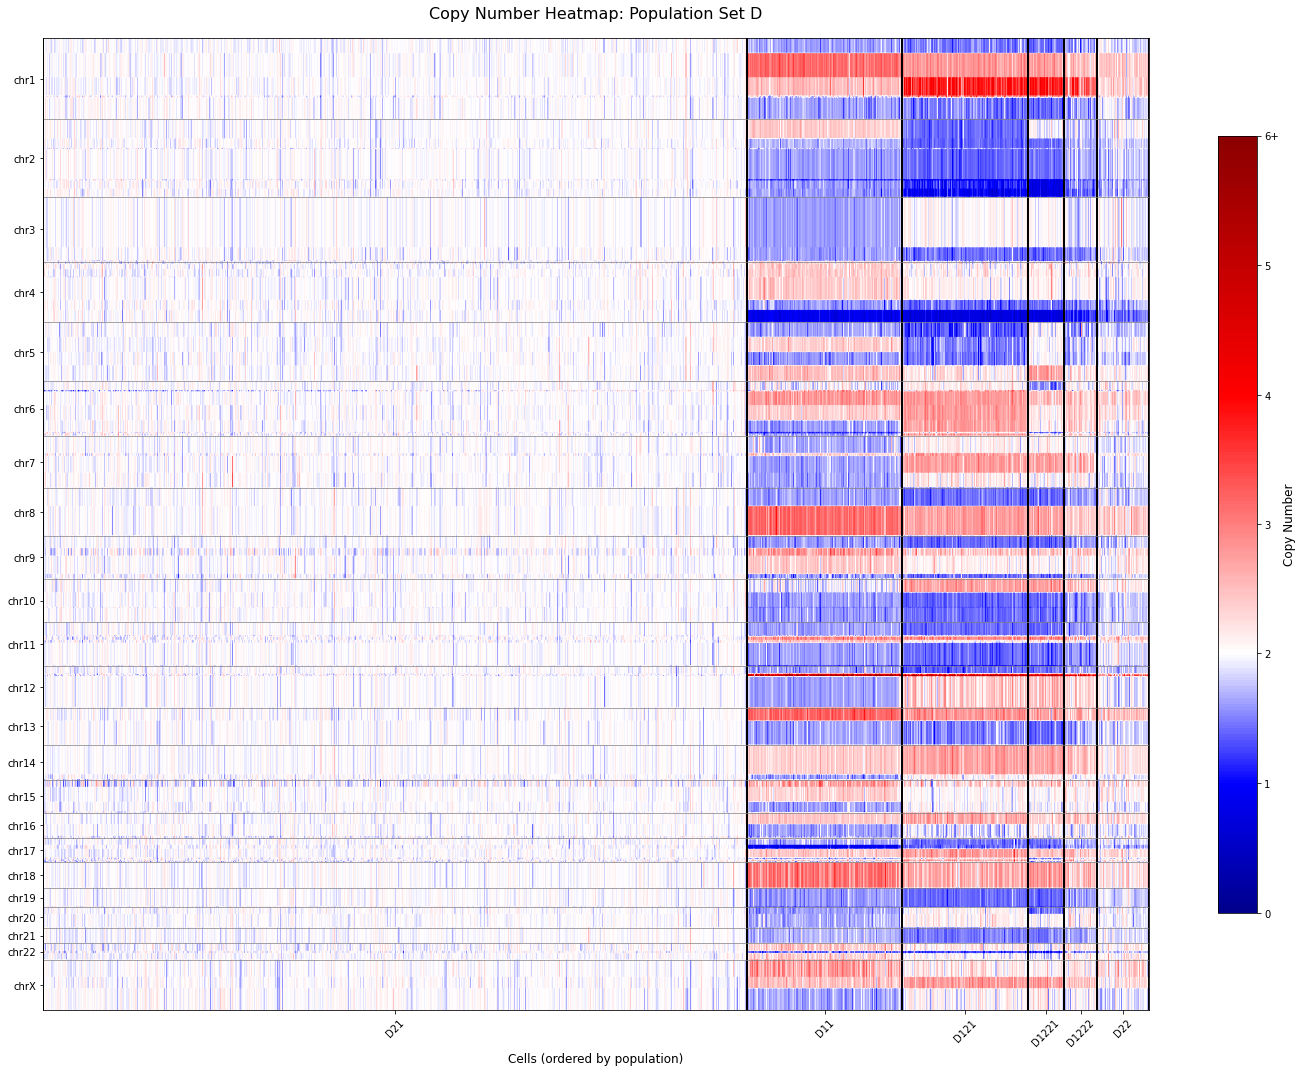

In [53]:
plot_copy_number_heatmap(
    heatmap_df_D, 
    boundaries_D, 
    segment_info_D,
    title="Copy Number Heatmap: Population Set D"
)

Expanding heatmap from 89 segments to 5431 rows...

Chromosome representation in heatmap:
chr1: 453 rows, 246,159,932 bp total
chr2: 434 rows, 235,824,599 bp total
chr3: 360 rows, 196,141,480 bp total
chr4: 339 rows, 183,819,298 bp total
chr5: 329 rows, 178,463,482 bp total
chr6: 307 rows, 166,930,960 bp total
chr7: 289 rows, 156,878,815 bp total
chr8: 268 rows, 145,153,934 bp total
chr9: 240 rows, 130,597,528 bp total
chr10: 244 rows, 132,750,269 bp total
chr11: 243 rows, 132,171,512 bp total
chr12: 234 rows, 127,192,322 bp total
chr13: 209 rows, 113,902,193 bp total
chr14: 194 rows, 105,604,444 bp total
chr15: 184 rows, 100,011,182 bp total
chr16: 142 rows, 77,331,877 bp total
chr17: 136 rows, 73,991,953 bp total
chr18: 143 rows, 77,454,799 bp total
chr19: 107 rows, 57,963,957 bp total
chr20: 114 rows, 61,810,229 bp total
chr21: 88 rows, 47,543,707 bp total
chr22: 92 rows, 49,488,653 bp total
chrX: 282 rows, 153,345,065 bp total


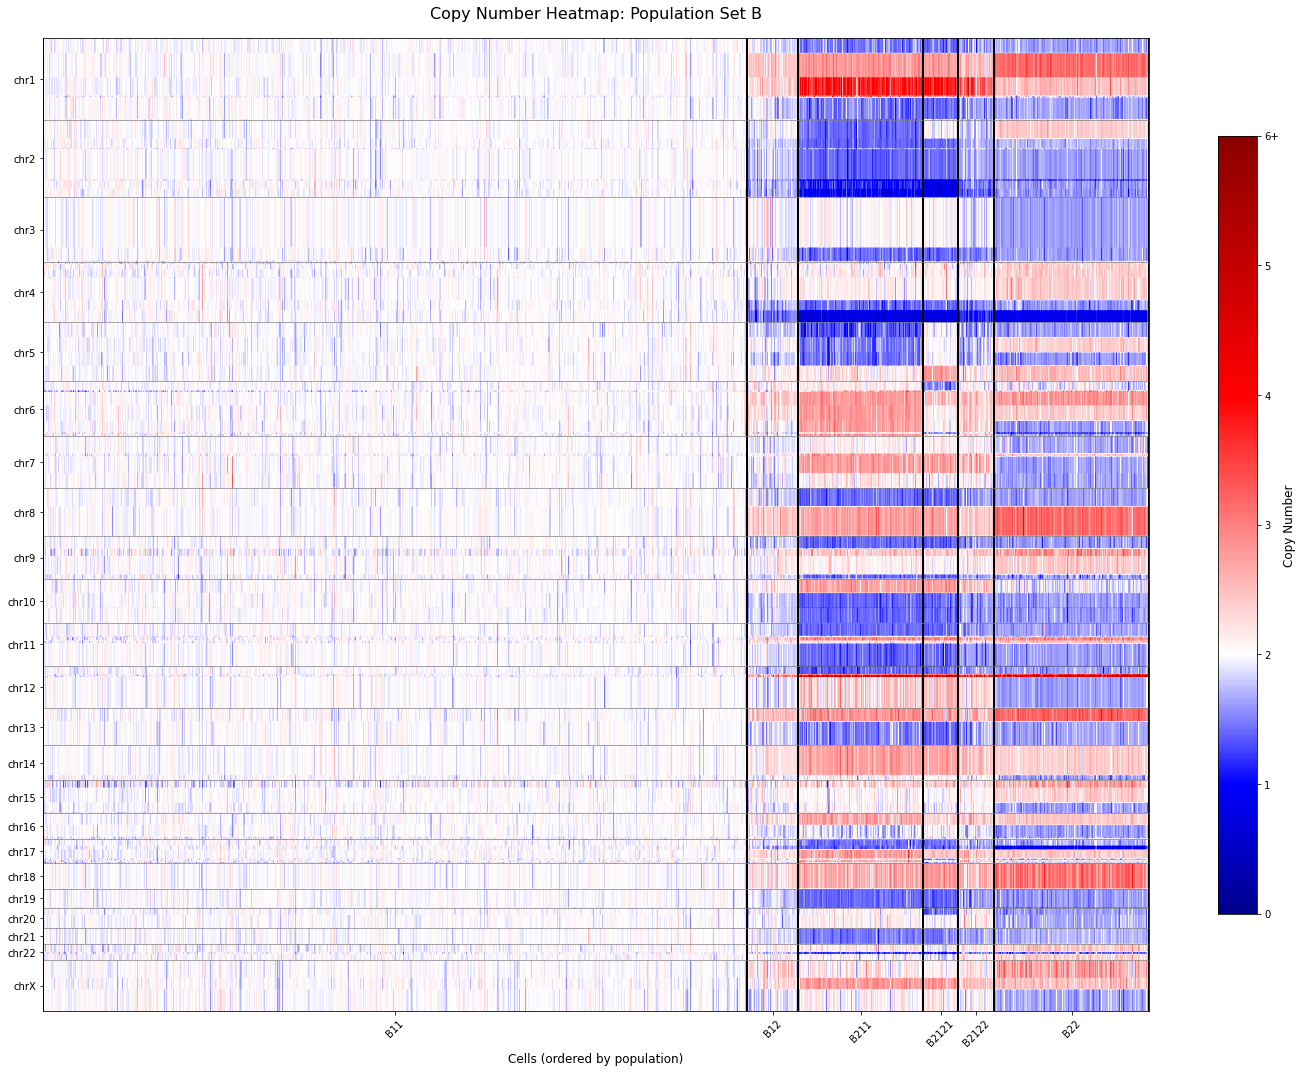

In [54]:
plot_copy_number_heatmap(
    heatmap_df_B, 
    boundaries_B, 
    segment_info_B,
    title="Copy Number Heatmap: Population Set B"
)

Expanding heatmap from 89 segments to 5431 rows...

Chromosome representation in heatmap:
chr1: 453 rows, 246,159,932 bp total
chr2: 434 rows, 235,824,599 bp total
chr3: 360 rows, 196,141,480 bp total
chr4: 339 rows, 183,819,298 bp total
chr5: 329 rows, 178,463,482 bp total
chr6: 307 rows, 166,930,960 bp total
chr7: 289 rows, 156,878,815 bp total
chr8: 268 rows, 145,153,934 bp total
chr9: 240 rows, 130,597,528 bp total
chr10: 244 rows, 132,750,269 bp total
chr11: 243 rows, 132,171,512 bp total
chr12: 234 rows, 127,192,322 bp total
chr13: 209 rows, 113,902,193 bp total
chr14: 194 rows, 105,604,444 bp total
chr15: 184 rows, 100,011,182 bp total
chr16: 142 rows, 77,331,877 bp total
chr17: 136 rows, 73,991,953 bp total
chr18: 143 rows, 77,454,799 bp total
chr19: 107 rows, 57,963,957 bp total
chr20: 114 rows, 61,810,229 bp total
chr21: 88 rows, 47,543,707 bp total
chr22: 92 rows, 49,488,653 bp total
chrX: 282 rows, 153,345,065 bp total


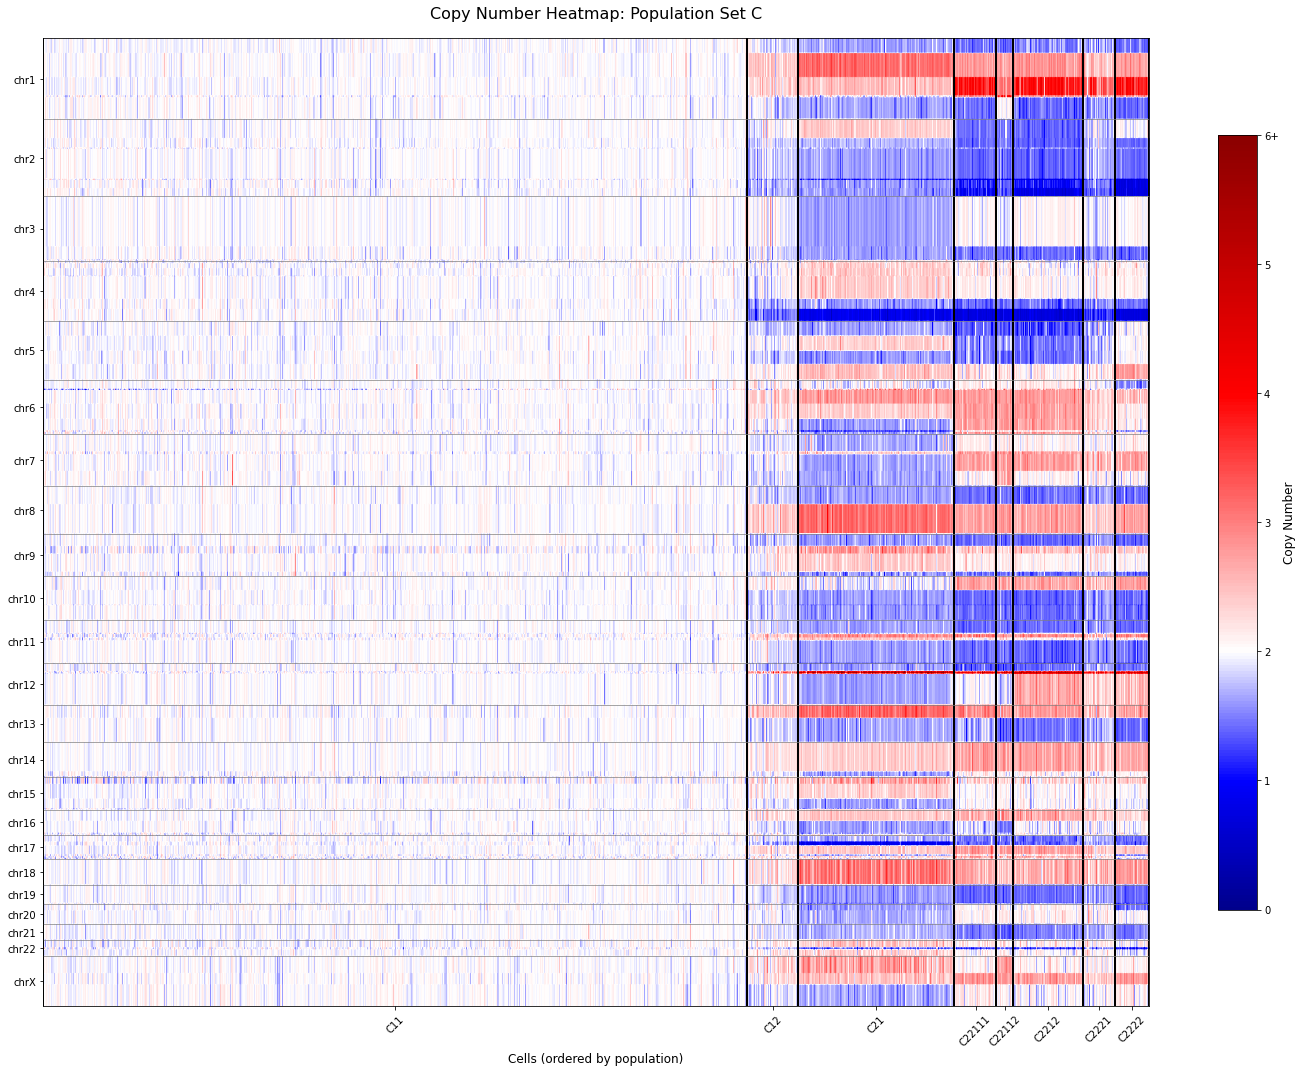

In [55]:
plot_copy_number_heatmap(
    heatmap_df_C, 
    boundaries_C, 
    segment_info_C,
    title="Copy Number Heatmap: Population Set C"
)

In [ ]:
bincounts.head()

In [56]:
def new_ratios_to_normal(ratios_to_normal, reassigned_populations, all_data, normal_pop_name):
    df = ratios_to_normal[['chrom', 'start', 'end']].copy()
    normal_cells = reassigned_populations[normal_pop_name]["cells"]
    normal_factor = all_data[normal_cells].mean(axis=1).values  # Average across normal cells for each segment
    normal_factor = np.where(normal_factor > 0, normal_factor, 1)  # Avoid division by zero
    normal_factor = np.where(normal_factor > 0, normal_factor, 0.1)  # Avoid division by zero
    normal_factor = normal_factor/normal_factor.mean() 
    for clusters in reassigned_populations:
        cells = reassigned_populations[clusters]["cells"]
        df[clusters] = all_data[cells].mean(axis=1)
        df[clusters] = df[clusters]/df[clusters].mean(axis=0)
        df[clusters] = df[clusters]/normal_factor
    return df
    

In [57]:
df_A = new_ratios_to_normal(ratios_A, A_dict, all_data, normal_A)

In [58]:
df_A.head()

,chrom,start,end,A1111,A1112,A1121,A11221,A11222,A121,A122,A21,A22
0,chr1,0,45387037,0.724463,0.833180,0.789840,0.725065,0.703430,0.815795,0.830873,0.926964,1.0
1,chr1,45972336,119478274,1.366137,1.221608,1.423758,1.378565,1.344453,1.557818,1.559812,1.188352,1.0
2,chr1,120035598,175362842,1.876361,1.583615,1.890616,1.925608,1.476905,1.236449,1.254298,1.172505,1.0
3,chr1,175900450,182029442,1.354482,1.243827,1.368291,1.406891,1.829294,1.172378,0.884664,1.073663,1.0
4,chr1,182578512,248389233,0.697243,0.812419,0.692087,0.721493,1.017987,0.791869,0.827992,0.919636,1.0


In [59]:
def plot_ratios_histograms(df, reassigned_populations):
    for cluster in reassigned_populations:
        plt.figure(figsize=(10, 5))
        plt.hist(df[cluster].values, bins=50)
        plt.title(cluster)
        plt.xlim(0,3)

    #Make a nice plot for the above histograms
    plt.figure(figsize=(12, 6))
    for i, cluster in enumerate(reassigned_populations):
        plt.subplot(1, len(reassigned_populations), i+1)
        plt.hist(df[cluster], bins=50, color='blue', alpha=0.7)
        plt.title(cluster)
        plt.xlabel('Normalized Read Count')
        plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

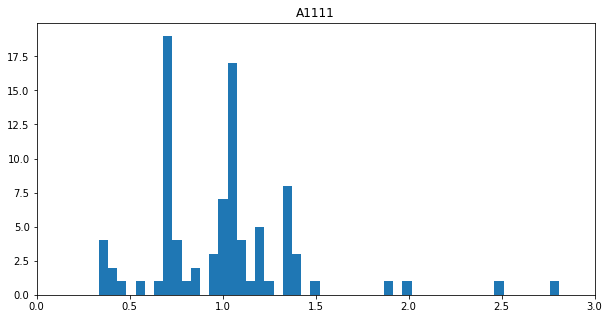

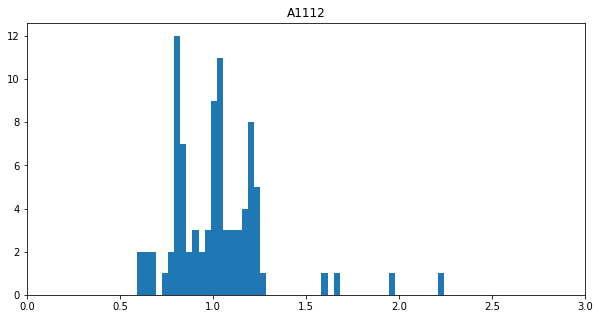

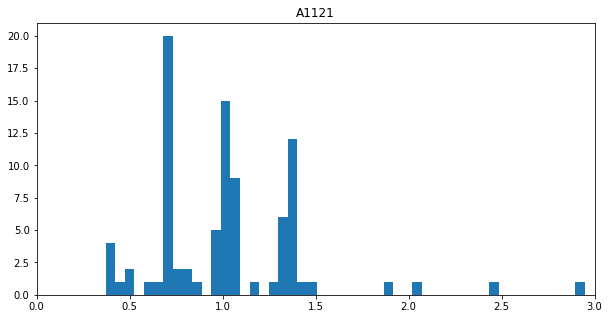

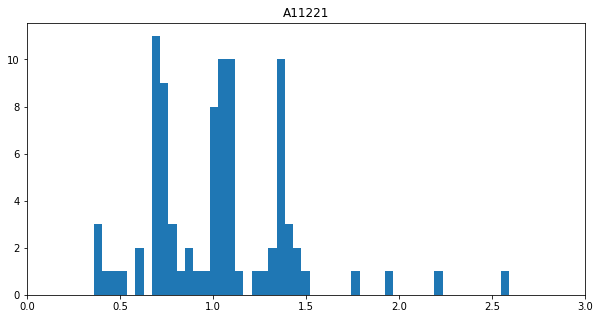

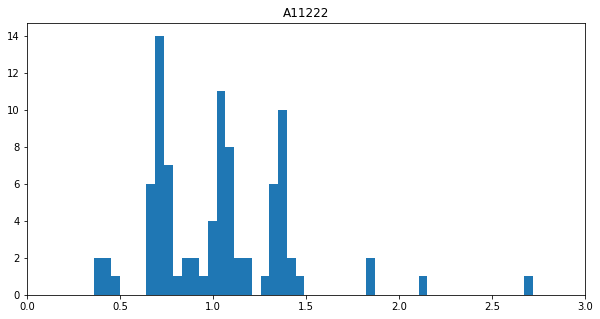

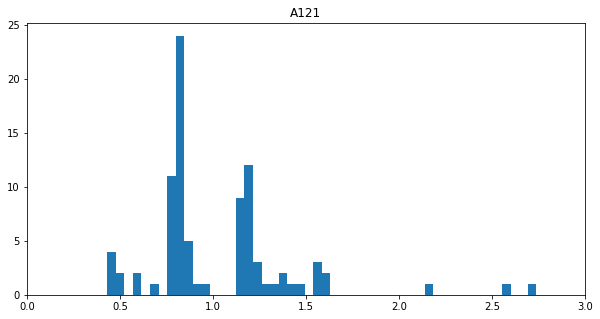

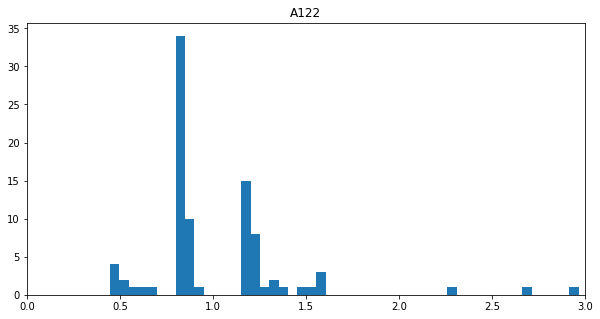

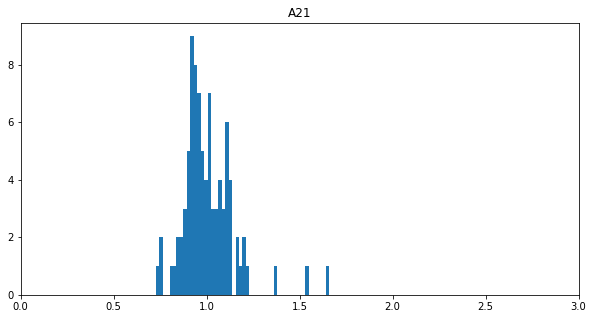

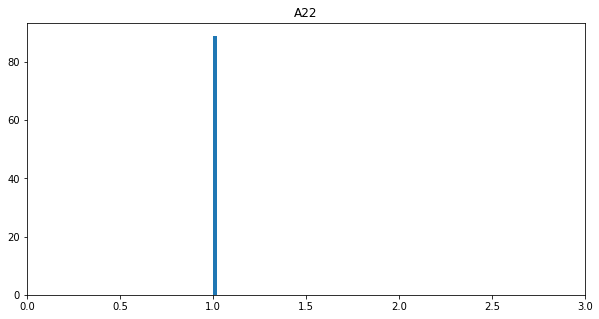

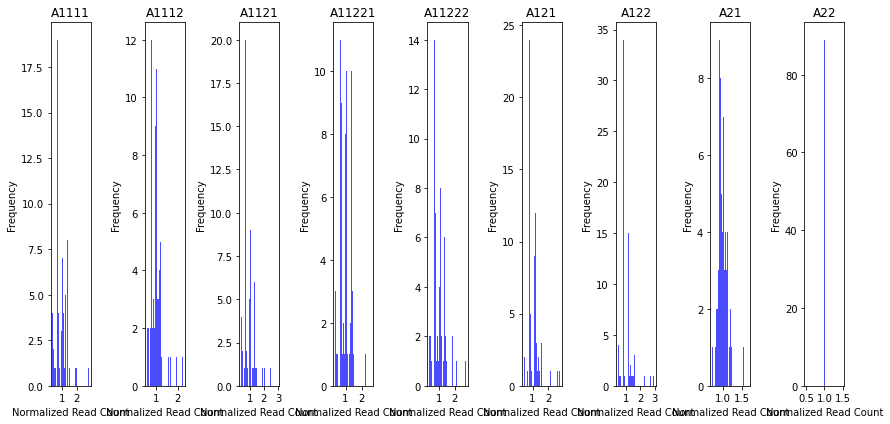

In [60]:
plot_ratios_histograms(df_A, A_dict)

0


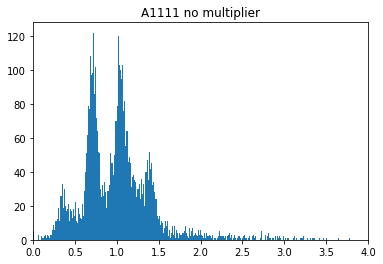

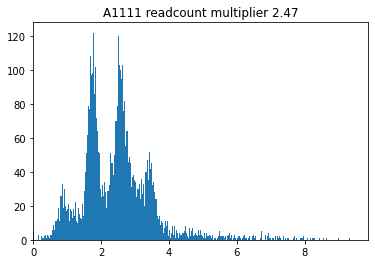

28


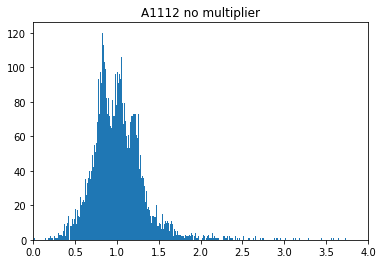

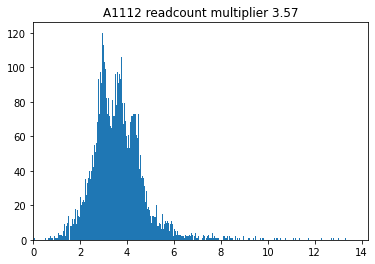

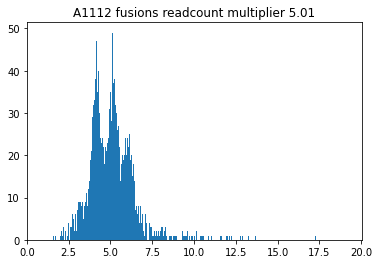

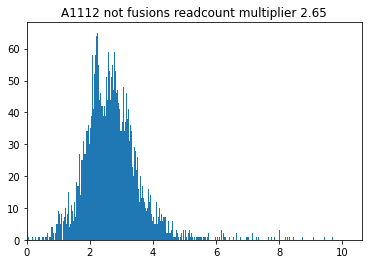

1


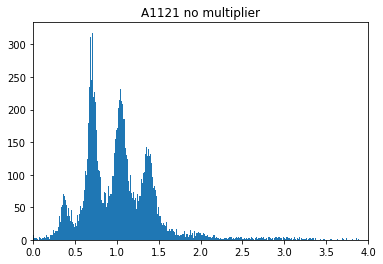

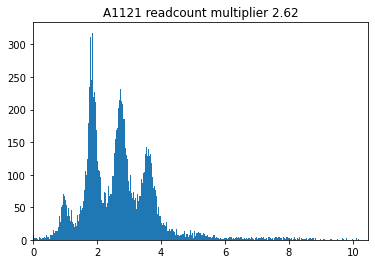

0


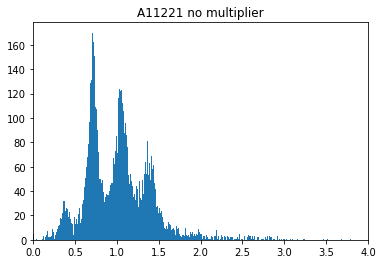

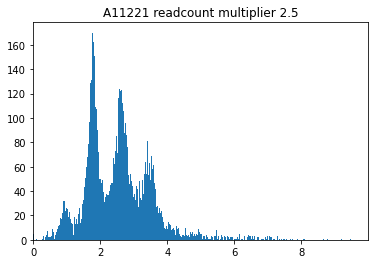

1


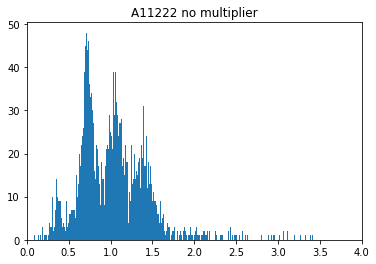

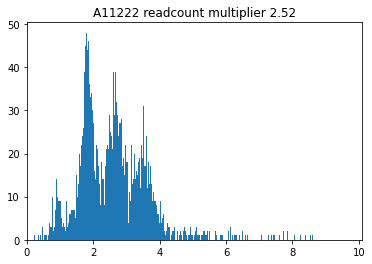

3


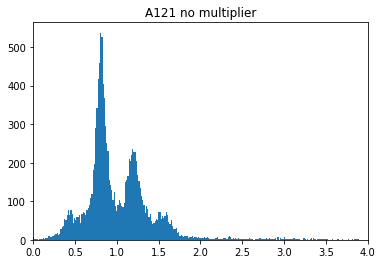

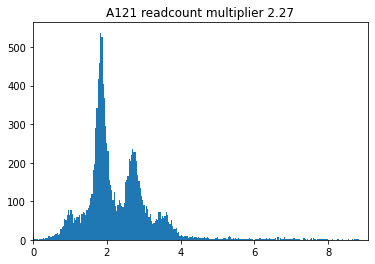

11


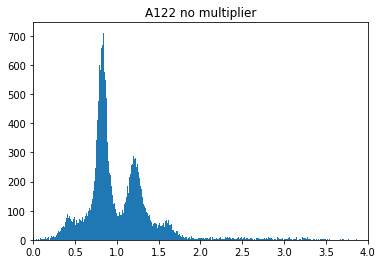

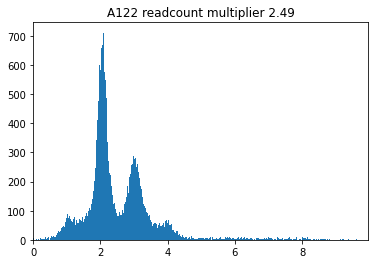

50


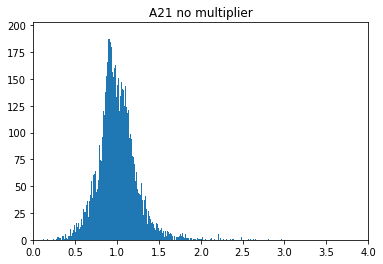

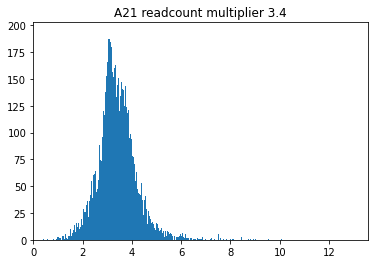

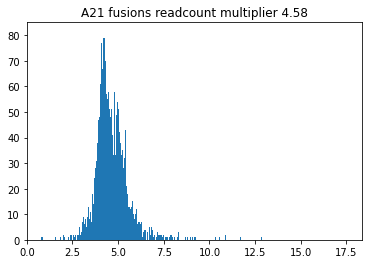

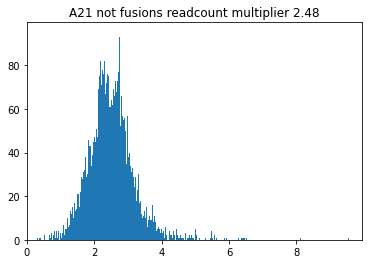

6


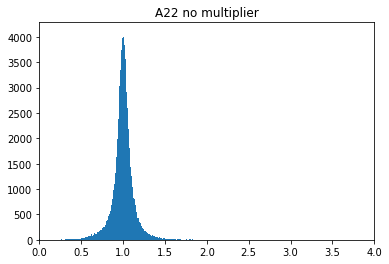

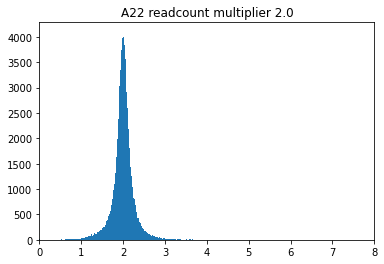

In [ ]:
normal_A_readcount = np.mean([readcount_dict[cell] for cell in A_dict[normal_A]["cells"]])
for cluster in A_dict:
    cells = A_dict[cluster]["cells"]
    fusions = [c for c in cells if "_" in c]
    not_fusions = [c for c in cells if "_" not in c]
    print(len(fusions))
    plt.hist(normalized_data_D[cells].values.ravel(), bins =500)
    plt.title(cluster + " no multiplier")
    plt.xlim(0,4)
    plt.show()
    cluster_readcount = np.mean([readcount_dict[cell] for cell in cells])
    readcount_factor = (cluster_readcount/normal_A_readcount)*2
    plt.hist(normalized_data_D[cells].values.ravel()*readcount_factor, bins =500)
    plt.title(cluster + " readcount multiplier "+ str(round(readcount_factor, 2)))
    plt.xlim(0,4*readcount_factor)
    plt.show()
    if len(fusions) > 20:
        cluster_readcount = np.mean([readcount_dict[cell] for cell in fusions])
        readcount_factor = (cluster_readcount/normal_A_readcount)*2
        plt.hist(normalized_data_D[fusions].values.ravel()*readcount_factor, bins =500)
        plt.title(cluster + " fusions readcount multiplier "+ str(round(readcount_factor, 2)))
        #x ticks at integers
        plt.xticks(np.arange(0, 4*readcount_factor+1, 1))
        plt.xlim(0,4*readcount_factor)
        plt.show()
        cluster_readcount = np.mean([readcount_dict[cell] for cell in not_fusions])
        readcount_factor = (cluster_readcount/normal_A_readcount)*2
        plt.hist(normalized_data_D[not_fusions].values.ravel()*readcount_factor, bins =500)
        plt.title(cluster + " not fusions readcount multiplier "+ str(round(readcount_factor, 2)))
        plt.xlim(0,4*readcount_factor)
        plt.show()

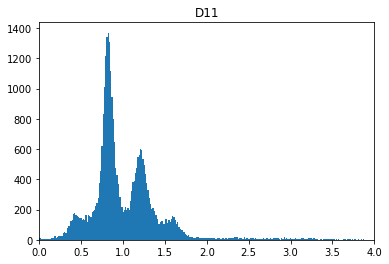

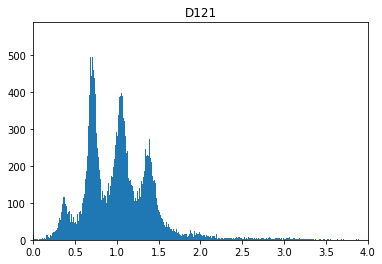

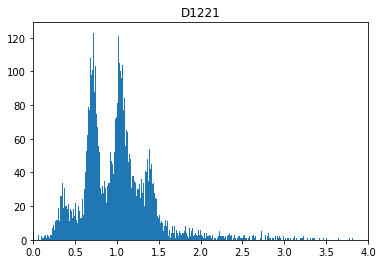

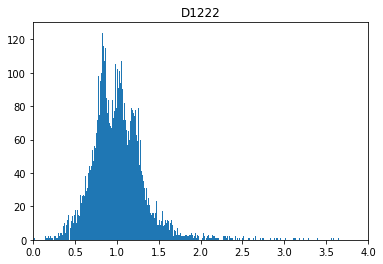

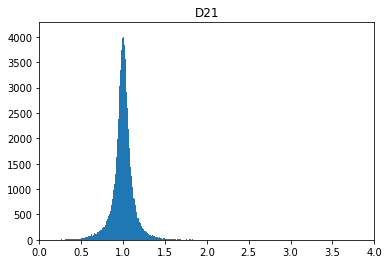

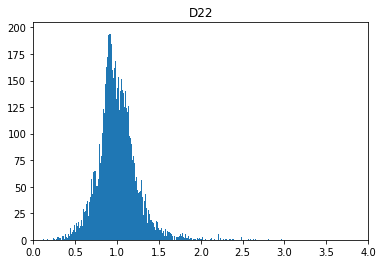

In [67]:
for cluster in D_dict:
    cells = D_dict[cluster]["cells"]
    plt.hist(normalized_data_D[cells].values.ravel(), bins =500)
    plt.title(cluster)
    plt.xlim(0,4)
    plt.show()

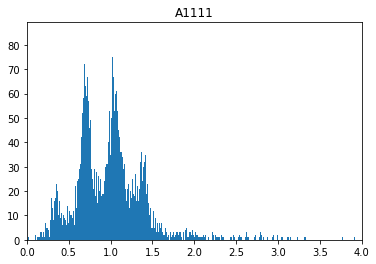

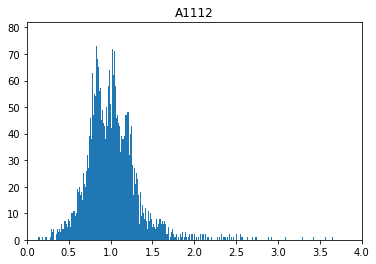

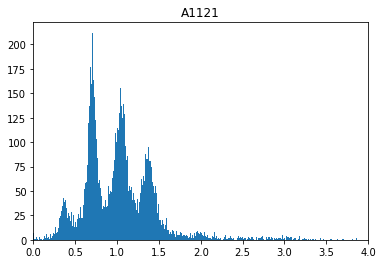

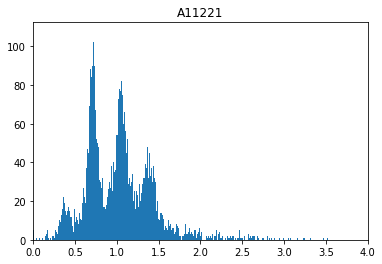

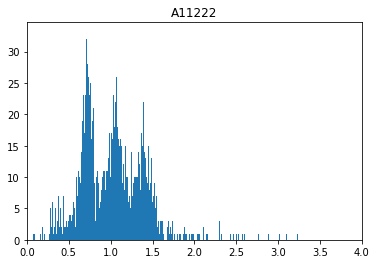

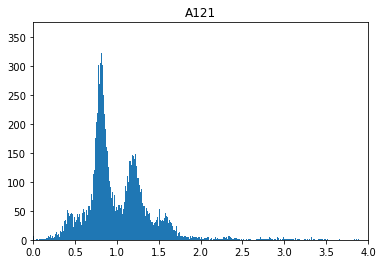

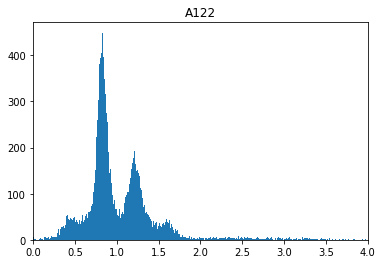

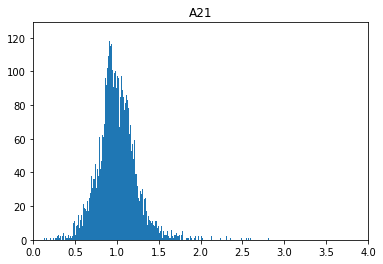

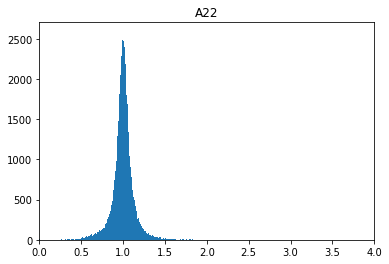

In [62]:
for cluster in A_dict:
    cells = A_dict[cluster]["cells"]
    plt.hist(normalized_data_A[cells].values.ravel(), bins =800)
    plt.title(cluster)
    plt.xlim(0,4)
    plt.show()

In [63]:
def histograms_from_bootstrap(all_data, normalized_data, reassigned_populations, normal_pop, n_boot=1000):
    normal_cells = reassigned_populations[normal_pop]["cells"]
    weights = all_data[normal_cells].mean(axis=1).values  # Average across normal cells for each segment
    weights = weights + 1e-12
    weights = weights / weights.sum()

    cluster_boot_distributions = {}

    for cluster in reassigned_populations:

        cells = reassigned_populations[cluster]["cells"]
        data = normalized_data[cells].values

        n_bins = data.shape[0]

        boot_values = []

        for _ in range(n_boot):

            sampled_bins = np.random.choice(
                np.arange(n_bins),
                size=n_bins,
                replace=True,
                p=weights
            )

            for b in sampled_bins:

                row = data[b]

                boot_sample = np.random.choice(
                    row,
                    size=len(row),
                    replace=True
                )

                boot_values.append(np.mean(boot_sample))

        cluster_boot_distributions[cluster] = np.array(boot_values)

    for cluster, vals in cluster_boot_distributions.items():

        plt.hist(vals, bins=200, density=True)
        plt.title(cluster)
        plt.xlim(0, 4)
        plt.show()
    return cluster_boot_distributions

        
    

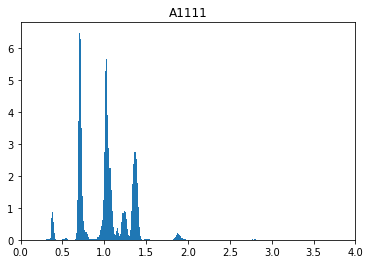

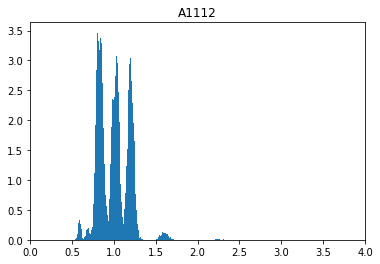

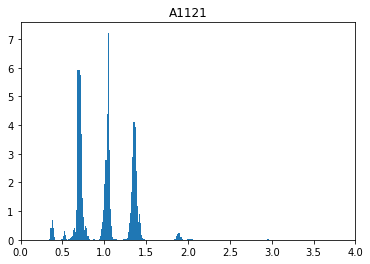

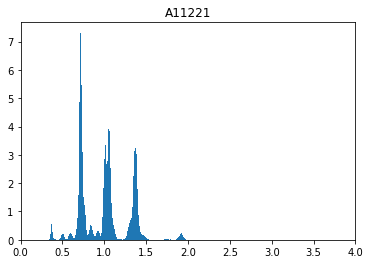

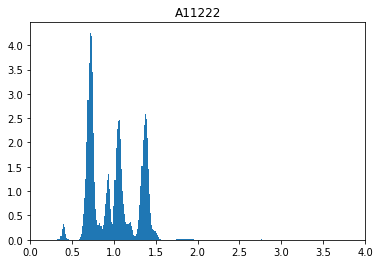

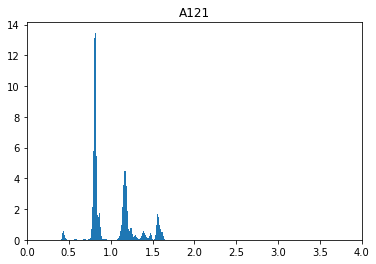

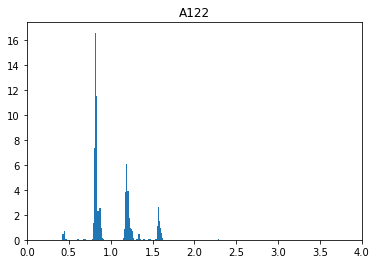

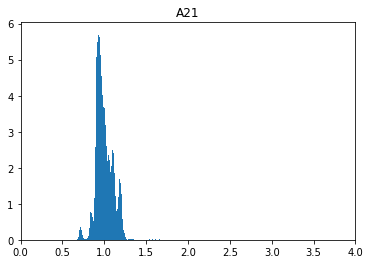

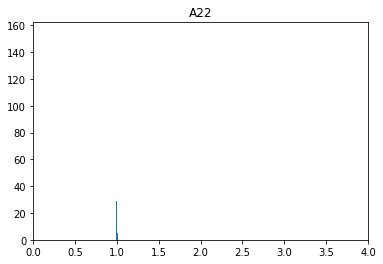

In [64]:
hist_A = histograms_from_bootstrap(all_data, normalized_data_A, A_dict, normal_A, n_boot=1000)

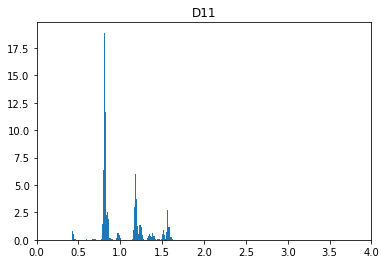

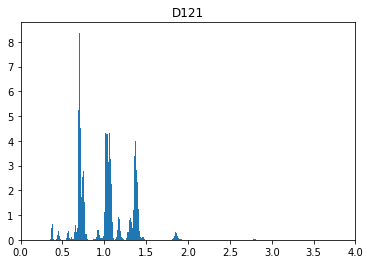

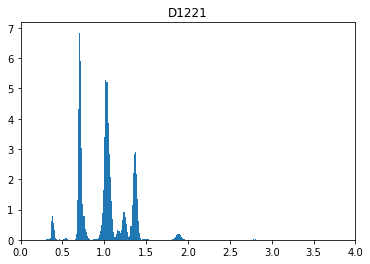

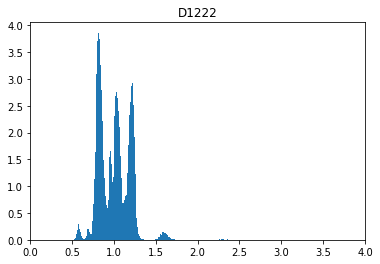

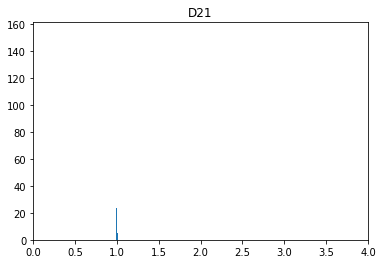

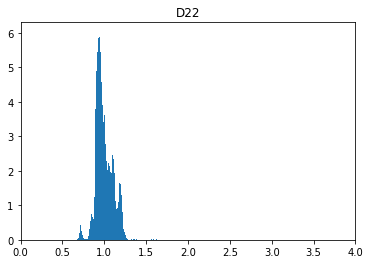

In [65]:
hist_D = histograms_from_bootstrap(all_data, normalized_data_D, D_dict, normal_D, n_boot=1000)

In [ ]:
cl = list(A_dict.keys())[0]

data = hist_A[cl]

kde = gaussian_kde(data)
xs = np.linspace(np.min(data), np.max(data), 2000)
ys = kde(xs)

mode_x = xs[np.argmax(ys)]

In [ ]:
hist_B = histograms_from_bootstrap(all_data, normalized_data_B, B_dict, normal_B, n_boot=1000)
hist_C = histograms_from_bootstrap(all_data, normalized_data_C, C_dict, normal_C, n_boot=1000)

In [ ]:
def plot_hist_with_integer_peaks(hist_A, A_dict, normalized_data_A, save_fig = False):
    for cl in A_dict.keys():

        data = hist_A[cl]

        kde = gaussian_kde(data)
        xs = np.linspace(np.min(data), np.max(data), 2000)
        ys = kde(xs)

        mode_x = xs[np.argmax(ys)]

        for i in range(1,5):
            multiplier = i/mode_x
            plt.hist((data * multiplier), bins = 200)
            plt.title(cl + " multiplier = " + str(round(multiplier, 2)))
            plt.xlim(0,3*i)
            plt.savefig("../figures/"+tumor+"/CN_histograms/"+cl+"_multiplier_"+str(round(i/mode_x, 2))+".png")
            plt.show()
            cells = A_dict[cl]["cells"]
            plt.hist(normalized_data_A[cells].values.ravel()*multiplier, bins =800)
            plt.title(cl + " multiplier = " + str(round(multiplier, 2)))
            if save_fig:
                plt.savefig("../figures/"+tumor+"/CN_histograms/"+cl+"_multiplier_"+str(round(multiplier, 2))+"_all_cells_normalized_data.png")
            plt.xlim(0,3*i)
            plt.show()
            
    

In [ ]:
#plot_hist_with_integer_peaks(hist_D, D_dict, normalized_data_D)

In [ ]:
plot_hist_with_integer_peaks(hist_A, A_dict, normalized_data_A)

In [ ]:
for cl in A_dict.keys():

    data = hist_A[cl]

    kde = gaussian_kde(data)
    xs = np.linspace(np.min(data), np.max(data), 2000)
    ys = kde(xs)

    mode_x = xs[np.argmax(ys)]

    for i in range(1,5):
        plt.hist((data/mode_x)*i, bins = 200)
        plt.title(cl + " multiplier = " + str(round(i/mode_x, 2)))
        plt.xlim(0,3*i)
        plt.show()

In [ ]:
plt.hist((data/mode_x)*2, bins = 200)

In [ ]:
n_boot = 1000
cluster_boot_distributions = {}

# ----------------------------------------
# weights from normal_A
# ----------------------------------------
normal_cells = A_dict[normal_A]["cells"]
weights = all_data[normal_cells].mean(axis=1).values.astype(float)

weights = weights + 1e-12
weights = weights / weights.sum()

# ----------------------------------------
# bootstrap per cluster
# ----------------------------------------
for cluster in A_dict:

    cells = A_dict[cluster]["cells"]

    data = normalized_data_A[cells].values

    n_bins = data.shape[0]

    boot_values = []

    for _ in range(n_boot):

        sampled_bins = np.random.choice(
            np.arange(n_bins),
            size=n_bins,
            replace=True,
            p=weights
        )

        for b in sampled_bins:

            row = data[b]

            boot_sample = np.random.choice(
                row,
                size=len(row),
                replace=True
            )

            boot_values.append(np.mean(boot_sample))

    cluster_boot_distributions[cluster] = np.array(boot_values)



In [ ]:
# ----------------------------------------
# plot
# ----------------------------------------
for cluster, vals in cluster_boot_distributions.items():

    plt.hist(vals, bins=200, density=True)
    plt.title(cluster)
    plt.xlim(0, 5)
    plt.show()

In [ ]:
df_D = new_ratios_to_normal(ratios_D, D_dict, all_data, normal_D)

In [ ]:
plot_ratios_histograms(df_D, D_dict)

In [ ]:
cells_hist_data_A = {}
for cluster in A_dict:
    cells = A_dict[cluster]["cells"]
    plt.hist(normalized_data_A[cells].values.ravel(), bins =800)
    cells_hist_data_A[cluster] = normalized_data_A[cells].values.ravel()
    plt.title(cluster)
    plt.xlim(0,4)
    plt.show()

In [ ]:
cl = list(A_dict.keys())[0]
#cl = normal_A
data = cells_hist_data_A[cl]

In [ ]:
kde = gaussian_kde(data)

x = np.linspace(data.min(), data.max(), 5000)
y = kde(x)

peak_idx, _ = find_peaks(y, prominence=0.05*np.max(y))

peak_x = x[peak_idx]
peak_heights = y[peak_idx]

In [ ]:
plt.hist(data, bins=800, density=True)
plt.plot(x, y, color='red')
for x_val in peak_x:
    plt.axvline(x=x_val, color='black', linestyle='--', label=f'Peak at {x_val:.2f}')

In [ ]:
def score(m, peak_locations, peak_heights):
    scaled = m * peak_locations
    return np.sum(
        peak_heights *
        (scaled - np.round(scaled))**2
    )



In [ ]:
def find_best_multiplier(
    peak_locations,
    peak_heights,
    min_m=1.5,
    max_m=5.0,
    n_grid=2000,
    prominence=0.08,
    rel_count = None
):

    """
    Returns:
        best_m: float
        local_minima: list of (m, score), sorted by score ascending
    """
    # 1) coarse scan
    m_grid = np.linspace(min_m, max_m, n_grid)
    score_grid = np.array([score(m, peak_locations, peak_heights) for m in m_grid])

    # 2) local minima = peaks of -score
    minima_idx, _ = find_peaks(-score_grid, prominence=prominence)

    # include boundary minima if needed
    if score_grid[0] < score_grid[1]:
        minima_idx = np.r_[0, minima_idx]
    if score_grid[-1] < score_grid[-2]:
        minima_idx = np.r_[minima_idx, len(score_grid) - 1]

    # keep minima in index order (scan order)
    minima_idx = np.array(minima_idx, dtype=int)
    minima_idx.sort()

    local_minima = [(float(m_grid[i]), float(score_grid[i])) for i in minima_idx]

    # best_m from global grid minimum (not just local minima)
    
    #If rel_count is not None, we want to find the best multiplier that gives us a peak closest to rel_count
    if rel_count is not None:
        best_m = min(local_minima, key=lambda x: abs(x[0] - rel_count))[0]
    else:
        best_idx = np.argmin(score_grid)
        best_m = float(m_grid[best_idx])

    return best_m, local_minima


In [ ]:
def find_multipliers_for_clusters(cells_hist_data, cluster_names, relative_counts=None):
    multipliers = {}
    local_minima_dict = {}
    for cluster in cluster_names:
        data = cells_hist_data[cluster]
        kde = gaussian_kde(data)
        x = np.linspace(data.min(), data.max(), 5000)
        y = kde(x)
        peak_idx, _ = find_peaks(y, prominence=0.05*np.max(y))
        peak_x = x[peak_idx]
        peak_heights = y[peak_idx]
        if relative_counts is not None and cluster in relative_counts:
            rel_count = relative_counts[cluster]*2
            best_m, local_minima = find_best_multiplier(peak_x, peak_heights, rel_count=rel_count)
        else:
            best_m, local_minima = find_best_multiplier(peak_x, peak_heights)
        multipliers[cluster] = best_m
        local_minima_dict[cluster] = local_minima
        #multiply data by best_m and plot
        plt.hist(data*best_m, bins=800, density=True)
        plt.plot(x*best_m, y/best_m, color='red')
        for x_val in peak_x*best_m:
            plt.axvline(x=x_val, color='black', linestyle='--', label=f'Peak at {x_val:.2f}')
        plt.title(f"{cluster} with multiplier {best_m:.2f}")
        plt.xlim(0, 4*best_m)
        plt.show()

        plt.hist(data, bins=800, density=True)
        plt.plot(x, y, color='red')
        for x_val in peak_x:
            plt.axvline(x=x_val, color='black', linestyle='--', label=f'Peak at {x_val:.2f}')
        plt.xlim(0, 4)
        plt.show()
    return multipliers, local_minima_dict

In [ ]:
cells_hist_data_B = {}
for cluster in B_dict:
    cells = B_dict[cluster]["cells"]
    #plt.hist(normalized_data_B[cells].values.ravel(), bins =800)
    cells_hist_data_B[cluster] = normalized_data_B[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()
cells_hist_data_C = {}
for cluster in C_dict:
    cells = C_dict[cluster]["cells"]
    #plt.hist(normalized_data_C[cells].values.ravel(), bins =800)
    cells_hist_data_C[cluster] = normalized_data_C[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()
cells_hist_data_D = {}
for cluster in D_dict:
    cells = D_dict[cluster]["cells"]
    #plt.hist(normalized_data_D[cells].values.ravel(), bins =800)
    cells_hist_data_D[cluster] = normalized_data_D[cells].values.ravel()
    # plt.title(cluster)
    # plt.xlim(0,4)
    # plt.show()

In [ ]:
relative_counts_A

In [ ]:
multipliers_A, local_minima_dict_A = find_multipliers_for_clusters(cells_hist_data_A, A_dict.keys(), relative_counts=relative_counts_A)
multipliers_B, local_minima_dict_B = find_multipliers_for_clusters(cells_hist_data_B, B_dict.keys(), relative_counts=relative_counts_B)
multipliers_C, local_minima_dict_C = find_multipliers_for_clusters(cells_hist_data_C, C_dict.keys(), relative_counts=relative_counts_C)
multipliers_D, local_minima_dict_D = find_multipliers_for_clusters(cells_hist_data_D, D_dict.keys(), relative_counts=relative_counts_D)

In [ ]:
boot_multipliers_A, local_minima_dict_A = find_multipliers_for_clusters(hist_A, A_dict.keys(), relative_counts=relative_counts_A)
boot_multipliers_B, local_minima_dict_B = find_multipliers_for_clusters(hist_B, B_dict.keys(), relative_counts=relative_counts_B)
boot_multipliers_C, local_minima_dict_C = find_multipliers_for_clusters(hist_C, C_dict.keys(), relative_counts=relative_counts_C)
boot_multipliers_D, local_minima_dict_D = find_multipliers_for_clusters(hist_D, D_dict.keys(), relative_counts=relative_counts_D)

In [ ]:
multipliers_A

In [ ]:
local_minima_dict_A

In [ ]:
df = pd.read_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t")
df["hist_multiplier"] = df["pop_name"].map(multipliers_A)
df["boot_multiplier"] = df["pop_name"].map(boot_multipliers_A)
#df.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_A.txt", sep="\t", index=False)

In [ ]:
df[["hist_multiplier", "boot_multiplier"]]

In [ ]:
df = pd.read_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_B.txt", sep="\t")
df["hist_multiplier"] = df["pop_name"].map(multipliers_B)
df["boot_multiplier"] = df["pop_name"].map(boot_multipliers_B)
#df.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_B.txt", sep="\t", index=False)


In [ ]:
df[["hist_multiplier", "boot_multiplier"]]

In [ ]:
df = pd.read_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_C.txt", sep="\t")
df["hist_multiplier"] = df["pop_name"].map(multipliers_C)
df["boot_multiplier"] = df["pop_name"].map(boot_multipliers_C)
#df.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_C.txt", sep="\t", index=False)


In [ ]:
df[["hist_multiplier", "boot_multiplier"]]

In [ ]:
df = pd.read_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_D.txt", sep="\t")
df["hist_multiplier"] = df["pop_name"].map(multipliers_D)
df["boot_multiplier"] = df["pop_name"].map(boot_multipliers_D)
#df.to_csv(f"../data/{tumor}/{tumor}_ploidy_summary_table_D.txt", sep="\t", index=False)

In [ ]:
df[["hist_multiplier", "boot_multiplier"]]